<a href="https://colab.research.google.com/github/harleenk2295-cpu/c-practice/blob/main/Linear_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Intercept (b0): -0.35208245935487614
Slope(b1): 0.07513481041103555


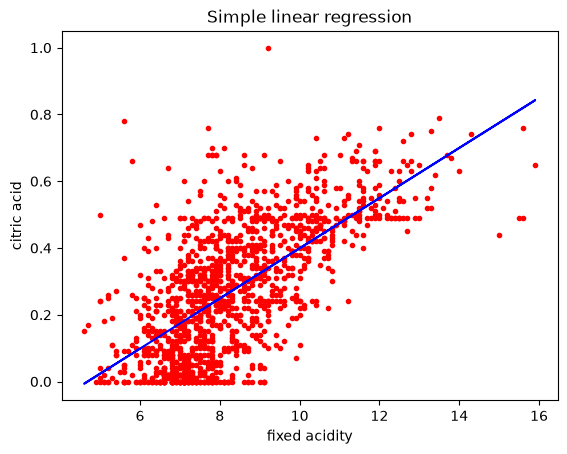

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
df=pd.read_csv('/home/student/2025510071/winequality-red.csv')
df=df.drop_duplicates()
def coeff(x,y):
    n=np.size(x)
    mx=np.mean(x)
    my=np.mean(y)
    ssxy=np.sum(x*y)-n*mx*my
    ssxx=np.sum(x*x)-n*mx*mx
    b1=ssxy/ssxx
    b0=my-b1*mx
    return (b0,b1)
def regression_line(x,y,b):
    plt.scatter(x,y,color='red',marker='.')
    pred=b[0]+b[1]*x
    plt.plot(x,pred,color='blue')
    plt.xlabel('fixed acidity')
    plt.ylabel('citric acid')
    plt.title('Simple linear regression')

x=df['fixed acidity']
y=df['citric acid']
b=coeff(x,y)
print("Intercept (b0):",b[0])
print("Slope(b1):",b[1])
regression_line(x,y,b)

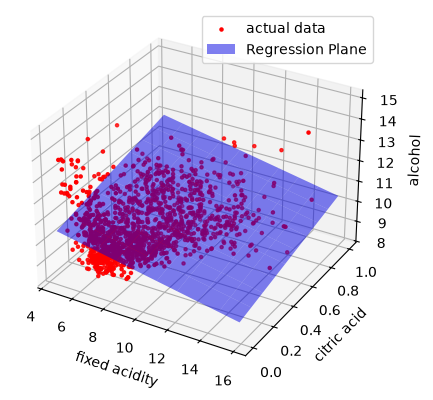

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
x=df[['fixed acidity','citric acid']]
y=df['alcohol']
xtrain,xtest,ytrain,ytest=train_test_split(x,y,test_size=0.2,random_state=42)
model=LinearRegression()
model.fit(xtrain,ytrain)
coeff=model.coef_
inter=model.intercept_
x1_range=np.linspace(x['fixed acidity'].min(),x['fixed acidity'].max(),10)
x2_range=np.linspace(x['citric acid'].min(),x['citric acid'].max(),10)
x1_mesh, x2_mesh = np.meshgrid(x1_range, x2_range)
z_mesh=inter+coeff[0]*x1_mesh+coeff[1]*x2_mesh
fig=plt.figure()
ax=fig.add_subplot(111,projection='3d')
ax.scatter(x['fixed acidity'],x['citric acid'],y,color='r',marker='.',label='actual data')
ax.plot_surface(x1_mesh, x2_mesh, z_mesh, alpha=0.5, color='blue', label='Regression Plane')
ax.set_xlabel('fixed acidity')
ax.set_ylabel('citric acid')
ax.set_zlabel('alcohol')
plt.legend()
plt.show()

In [ ]:
from sklearn.metrics import mean_squared_error,mean_absolute_error,r2_score
x=df[['fixed acidity','citric acid','free sulfur dioxide','total sulfur dioxide']]
y=df['alcohol']
xtrain,xtest,ytrain,ytest=train_test_split(x,y,test_size=0.2,random_state=42)
model=LinearRegression()
model.fit(xtrain,ytrain)
coef=model.coef_
inter=model.intercept_
pred=model.predict(xtest)
mse=mean_squared_error(ytest,pred)
mae=mean_absolute_error(ytest,pred)
r=r2_score(ytest,pred)
print(f"MSE:{mse},MAE:{mae},R SQUARED:{r}\n")
print(pred)

MSE:1.049221324095891,MAE:0.8240020783793618,R SQUARED:0.03743523308183894

[10.27073519 10.09891557 11.00446512 10.65564062 10.60799659 10.90901982
 10.67002291  9.55500214 10.53560211 10.92021108 10.82312409 10.6685414
 10.33049909 10.88769592 10.59784661  9.79054079 10.25118833 10.08028044
 10.40614144 11.04481476  9.23347365 10.69280711  9.83245073 10.4685903
 10.0967795   9.09278049 10.74457826 10.60297162 10.84696535 10.60247346
 10.38007551 11.03407242 10.48245324 10.1111444  10.63890952 10.41558334
 10.27088052 11.31763457 10.72243348 10.3547212  10.83392306 10.37702602
 10.74304201  9.14310807 10.31764732 10.57899315 10.30312013  9.19536777
 10.2303307  10.66328642 10.48331941  9.94339139 10.91373898 10.67757424
 10.75084812  9.65731763  9.97308346 10.45201928  9.83641872  9.69168166
  9.8836216  10.37047092 10.30855796 11.06992381 10.32045675 10.66001072
 10.71240644 10.84254982 10.40772212 10.52727509 10.48946717  9.9938187
  9.95309359 10.73100944 10.79360008 10.11223902  9

/home/student/2025510071/env22/lib/python3.14/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(


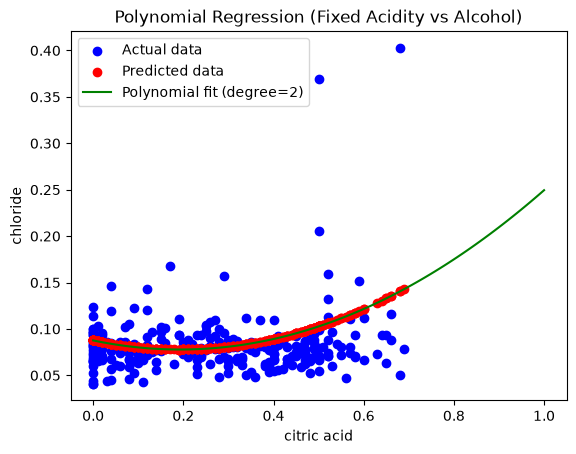

In [ ]:
from sklearn.preprocessing import PolynomialFeatures
x=df[['citric acid']]
y=df['chlorides']
xtrain,xtest,ytrain,ytest=train_test_split(x,y,test_size=0.2,random_state=42)
degree=2
poly=PolynomialFeatures(degree)
xtrainpoly=poly.fit_transform(xtrain)
xtestpoly=poly.transform(xtest)
model=LinearRegression()
model.fit(xtrainpoly,ytrain)
pred=model.predict(xtestpoly)
plt.scatter(xtest, ytest, color='blue', label='Actual data')
plt.scatter(xtest, pred, color='red', label='Predicted data')
x_range = np.linspace(x.min(), x.max(), 100)
x_range_poly = poly.transform(x_range)
y_range_pred = model.predict(x_range_poly)
plt.plot(x_range, y_range_pred, color='green', label=f'Polynomial fit (degree={degree})')
plt.xlabel('citric acid')
plt.ylabel('chloride')
plt.title('Polynomial Regression (Fixed Acidity vs Alcohol)')
plt.legend()
plt.show()